In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

1. 데이터 전처리.

• length,weight 합치기.
• 라벨값 생성.

1. 표준점수 적용.
2. 훈련데이터,테스트데이터 분리.
3. 데이터학습.
4. 데이터예측.
5. 정확도.
6. 그래프 출력.

In [3]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어 - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

In [4]:
# 표준 점수를 적용해서 전체 데이터와 [25,120] 를 scatter 그래프에 출력하시오.

1. 데이터 전처리

In [5]:
# 데이터 합해서 정리
length = bream_length+smelt_length
weight = bream_weight+smelt_weight

# data = [[l,w] for l,w in zip(length,weight)] -> 리스트 내포
label = [1]*35+[0]*14

# numpy로
# np.ones(35): 값이 1인 배열 35개, np.zeros(14): 값이 0인 배열 14개/ np.concatenate(): 두 배열을 이어 붙이기
# 문제의 순서와 정답의 순서가 맞아야 한다
data=np.column_stack((length,weight))
# label=np.concatenate((np.ones(35),np.zeros(14)))

In [6]:
# 정규화가 안된 형태 - 훈련데이터, 테스트 데이터 분리

train_data,test_data,train_label,test_label = \
train_test_split(data,label,stratify=label, test_size=0.2)

In [7]:
# # 표준점수 구하기

# # 길이의 평균과 무게의 평균을 각각 구합니다.-> 세로값 길이or 무게 //개수
# mean=np.mean(data,axis=0)
# # 길이의 표준편차와 무게의 표준편차를 각각 구합니다.-> 데이터가 평균 주변에 얼마나 퍼져 있는지를 나타내는 값
# std=np.std(data, axis=0)

# # 물고기마다 길이와 무게를 각각 표준점수로 바꿉니다.
# train_scaled=(data-mean)/std
# # 새 물고기도 같은 평균과 표준편차를 사용합니다.
# new_data=([25,120]-mean)/std

In [ ]:
from sklearn.preprocessing import StandardScaler
# 규제, 정규화작업 : 위 표준점수 구하는걸 자동으로 해주는 함수

ss=StandardScaler()
# 
# ss.fit()은 학습용 데이터의 평균과 표준편차를 구해 기억하는 작업
# transform()은 기억한 기준으로 값을 바꿉니다.
ss.fit(train_data) # 정규화 데이터로 훈련시켜줌.
train_scaled=ss.transform(train_data) #[길이 평균, 무게평균]-> 물고기 수만큼 행이 있음
test_scaled=ss.transform(test_data)   #[길이 표준편차, 무게 표준편차]
new_scaled=ss.transform([[25,120]])
new_scaled

array([[-0.16673037, -0.9945702 ]])

In [ ]:
# 데이터 학습
clf = KNeighborsClassifier()
clf.fit(train_scaled,train_label)
# 데이터 예측
result = clf.predict(test_scaled)
# 정확도
score = clf.score(test_scaled,test_label)
print("예측 : ",score)

예측 :  1.0


In [11]:
#  kneighbors 알고리즘 사용시 사용함.
distances,indexes = clf.kneighbors(new_scaled)
indexes

array([[36, 12, 11, 17, 33]])

In [12]:
new_scaled

array([[-0.16673037, -0.9945702 ]])

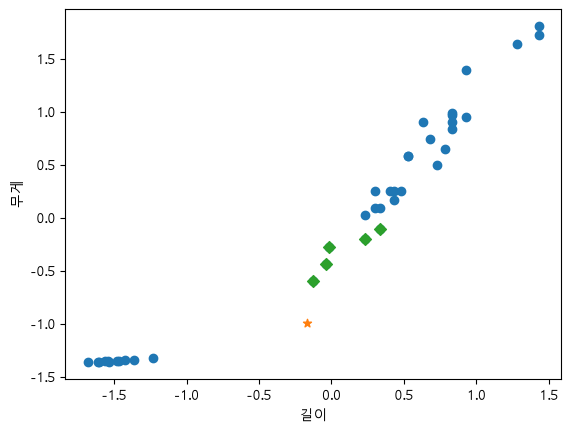

In [ ]:
# train_scaled[:,0]: 모든 물고기의 길이 표준점수, train_scaled[:,1] : 모든 물고기의 무게 표준점수
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1],marker='*')
# 모델이 참고할 가까운 이웃을 마름모 모양으로 표시
plt.scatter(train_scaled[indexes,0],train_scaled[indexes,1],marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()